# code_136 · Quadrature graph kernels on irregular and notched domains

**Book:** section 26.4. A self-contained operator-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_26_GUIDE.md), [run evidence](../CHAPTER_26_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_136).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3136;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3136


<a id="geometry-operator-contract"></a>
 ## Geometry, measures and boundary semantics travel with the field
 Native linear triangular finite elements solve −k*Laplace(u)=f on rectangles with zero Dirichlet boundaries. Source32/development8/final8 cases have independently jittered5-by-5 node grids, widths/heights0.8–1.2, scalar material k0.7–1.3 and smooth varying load amplitudes. Twelve further final cases remove the upper-right quarter to make an unseen L-shaped domain. Triangulation rejects triangles spanning the notch; boundary edges are detected from the retained mesh. A dense graph-integral kernel MLP integrates source forcing with lumped nodal area weights and sets boundary-node predictions to zero. Its eleven geometric/material pair features include positions, relative positions, boundary distance, lengths and k. Two rates0.003/0.01 receive400 updates, with their own whole-case development checkpoint every20updates. No notched-domain label selects a model.


,cohort,cases,node_counts,mean_case_field_MSE,mean_interior_MSE,max_boundary_defect
0,"Rectangle final, irregular25",8,"[25, 25, 25, 25, 25, 25, 25, 25]",0.000010,0.000027,0.0
1,"Rectangle final, regular81",8,"[81, 81, 81, 81, 81, 81, 81, 81]",0.000022,0.000036,0.0
2,"Notched final, unseen geometry",12,"[21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21]",0.000042,0.000175,0.0


Permutation and quadrature: 1.3877787807814457e-17 0.004971010644879778


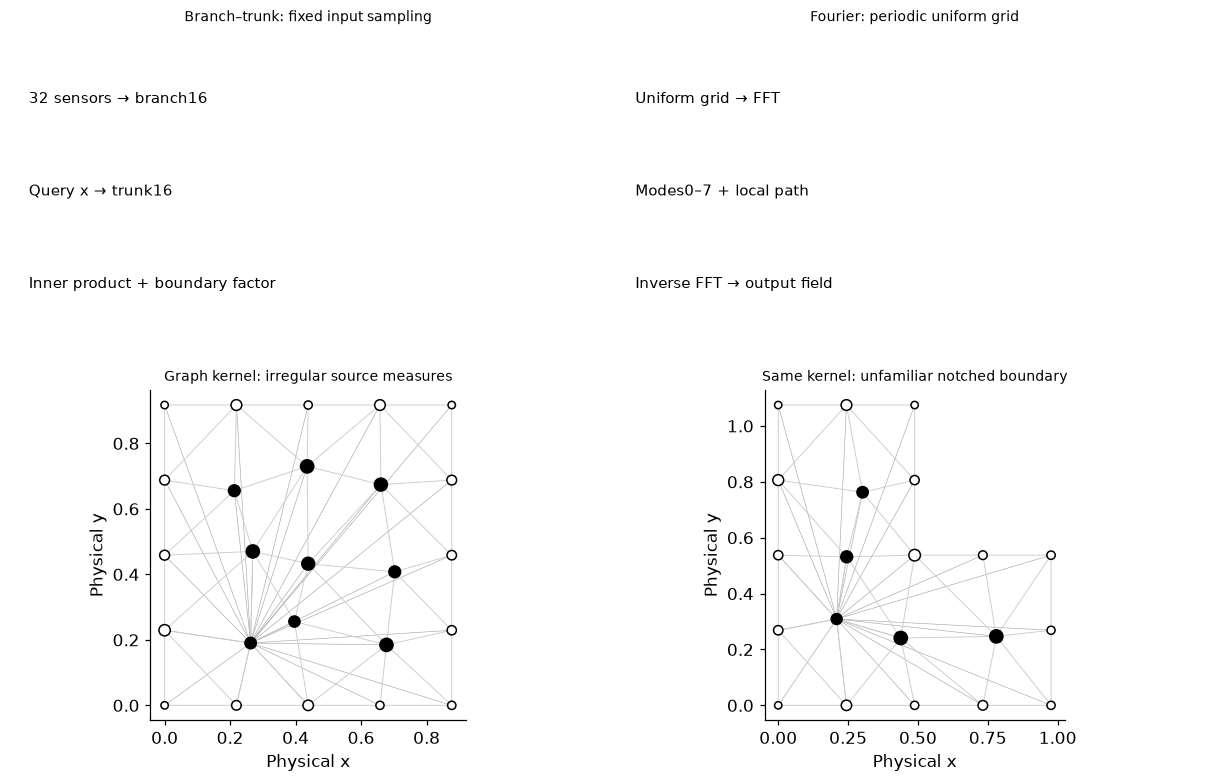

In [2]:
import copy
from scipy.spatial import Delaunay
from scipy.interpolate import LinearNDInterpolator
def domain_mesh(case,side=5,jitter=True):
    Lx,Ly,k,a,b,notch=case;coords=np.array([(i/(side-1)*Lx,j/(side-1)*Ly) for j in range(side) for i in range(side)])
    if jitter:
        interior=(coords[:,0]>0)&(coords[:,0]<Lx)&(coords[:,1]>0)&(coords[:,1]<Ly)
        if notch:interior&=~((np.isclose(coords[:,0],Lx/2)&(coords[:,1]>=Ly/2))|(np.isclose(coords[:,1],Ly/2)&(coords[:,0]>=Lx/2)))
        coords[interior]+=rng.uniform(-.06,.06,(interior.sum(),2))*np.array([Lx,Ly])
    if notch:coords=coords[~((coords[:,0]>Lx/2+1e-12)&(coords[:,1]>Ly/2+1e-12))]
    tri=Delaunay(coords).simplices;keep=[]
    for t in tri:
        v=coords[t];checks=np.vstack([v.mean(0),(v+np.roll(v,1,axis=0))/2])
        if not notch or not np.any((checks[:,0]>Lx/2+1e-12)&(checks[:,1]>Ly/2+1e-12)):keep.append(t)
    tri=np.array(keep);edge_counts={}
    for t in tri:
        for j in range(3):e=tuple(sorted([int(t[j]),int(t[(j+1)%3])]));edge_counts[e]=edge_counts.get(e,0)+1
    boundary_edges=[e for e,count in edge_counts.items() if count==1];boundary=np.zeros(len(coords),bool)
    for e in boundary_edges:boundary[list(e)]=True
    K=np.zeros((len(coords),len(coords)));weights=np.zeros(len(coords))
    for t in tri:
        v=coords[t];mat=np.column_stack([np.ones(3),v]);area=abs(np.linalg.det(mat))/2;grad=np.linalg.inv(mat)[1:,:].T;K[np.ix_(t,t)]+=k*area*(grad@grad.T);weights[t]+=area/3
    x,y=coords.T;forcing=a*(1+.4*np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly))+b*np.cos(2*np.pi*x/Lx)*np.cos(np.pi*y/Ly);u=np.zeros(len(coords));inside=~boundary;u[inside]=np.linalg.solve(K[np.ix_(inside,inside)],(weights*forcing)[inside]);assert np.all(weights>0) and np.any(inside)
    # Unsigned distance to the actual mesh boundary segments, known geometry only.
    distances=np.full(len(coords),np.inf)
    for e in boundary_edges:
        start,end=coords[list(e)];v=end-start;fraction=np.clip((coords-start)@v/(v@v),0,1);distances=np.minimum(distances,np.linalg.norm(coords-(start+fraction[:,None]*v),axis=1))
    return {'coords':coords,'triangles':tri,'boundary':boundary,'weights':weights,'forcing':forcing,'truth':u,'distance':distances,'case':case}
cases=np.column_stack([rng.uniform(.8,1.2,60),rng.uniform(.8,1.2,60),rng.uniform(.7,1.3,60),rng.uniform(.5,1.5,60),rng.uniform(-.3,.3,60),np.r_[np.zeros(48),np.ones(12)]])
meshes=[domain_mesh(c) for c in cases];scale=float(np.std(np.concatenate([m['truth'] for m in meshes[:32]])))
def pair_inputs(mesh):
    xy=mesh['coords'];Lx,Ly,k,*_=mesh['case'];q=xy[:,None,:];s=xy[None,:,:];n=len(xy);qn=np.broadcast_to(q/np.array([Lx,Ly]),(n,n,2));sn=np.broadcast_to(s/np.array([Lx,Ly]),(n,n,2));relative=(q-s)/np.array([Lx,Ly]);qd=np.broadcast_to(mesh['distance'][:,None,None],(n,n,1));sd=np.broadcast_to(mesh['distance'][None,:,None],(n,n,1));constants=np.broadcast_to(np.array([k,Lx,Ly]),(n,n,3));return np.concatenate([qn,sn,relative,qd,sd,constants],axis=-1)
class GraphKernel(nn.Module):
    def __init__(self):super().__init__();self.kernel=nn.Sequential(nn.Linear(11,16),nn.Tanh(),nn.Linear(16,16),nn.Tanh(),nn.Linear(16,1))
    def forward(self,features,weighted_forcing,interior):return scale*(self.kernel(features).squeeze(-1)@weighted_forcing)*interior
# Source rectangles all have25nodes; batch only compatible meshes for fitting.
F=torch.tensor(np.stack([pair_inputs(m) for m in meshes[:48]]));WF=torch.tensor(np.stack([m['forcing']*m['weights'] for m in meshes[:48]]));I=torch.tensor(np.stack([~m['boundary'] for m in meshes[:48]])).double();Y=torch.tensor(np.stack([m['truth'] for m in meshes[:48]]));best_family=np.inf;candidates=[]
for rate in [.003,.01]:
    torch.manual_seed(SEED);model=GraphKernel();opt=torch.optim.Adam(model.parameters(),lr=rate);best=np.inf
    for step in range(1,401):
        opt.zero_grad();p=model(F[:32],WF[:32,:,None],I[:32,:,None]).squeeze(-1);loss=((p-Y[:32])/scale).square().mean();loss.backward();opt.step()
        if step%20==0:
            with torch.no_grad():dp=model(F[32:40],WF[32:40,:,None],I[32:40,:,None]).squeeze(-1);score=float((dp-Y[32:40]).square().mean())
            if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
    candidates.append({'learning_rate':rate,'best_update':best_step,'development_MSE':best})
    if best<best_family:best_family=best;selected=(rate,best_step,state)
rate,best_step,state=selected;model.load_state_dict(state)
def predict(mesh,uniform=False):
    weights=np.full(len(mesh['weights']),mesh['weights'].sum()/len(mesh['weights'])) if uniform else mesh['weights']
    with torch.no_grad():return model(torch.tensor(pair_inputs(mesh)),torch.tensor(mesh['forcing']*weights),torch.tensor(~mesh['boundary']).double()).numpy()
rect_final=meshes[40:48];notched=meshes[48:];fine_meshes=[domain_mesh(c,9,False) for c in cases[40:48]];rows=[]
for cohort,group in [('Rectangle final, irregular25',rect_final),('Rectangle final, regular81',fine_meshes),('Notched final, unseen geometry',notched)]:
    predictions=[predict(m) for m in group];rows.append({'cohort':cohort,'cases':len(group),'node_counts':[len(m['coords']) for m in group],'mean_case_field_MSE':float(np.mean([np.mean((p-m['truth'])**2) for p,m in zip(predictions,group)])),'mean_interior_MSE':float(np.mean([np.mean((p[~m['boundary']]-m['truth'][~m['boundary']])**2) for p,m in zip(predictions,group)])),'max_boundary_defect':float(max(np.max(np.abs(p[m['boundary']])) for p,m in zip(predictions,group)))})
m=rect_final[0];p=predict(m);order=rng.permutation(len(p));permuted={**m,**{key:m[key][order] for key in ['coords','boundary','weights','forcing','truth','distance']}};permutation_error=float(np.max(np.abs(predict(permuted)-p[order])));assert permutation_error<1e-12
reference_refinement=[]
for original,finer in zip(rect_final[:2],fine_meshes[:2]):
    interpolated=LinearNDInterpolator(finer['coords'],finer['truth'])(original['coords']);assert np.isfinite(interpolated).all();reference_refinement.append(float(np.sqrt(np.mean((original['truth']-interpolated)**2))))
RESULTS.update(comparisons=rows,candidates=candidates,selected_rate=rate,best_update=best_step,parameters=sum(p.numel() for p in model.parameters()),case_counts=[32,8,8,12],permutation_max_difference=permutation_error,uniform_vs_area_quadrature_prediction_RMS=float(np.sqrt(np.mean((predict(m,True)-p)**2))),coarse_vs_finer_FEM_reference_RMS=reference_refinement,source_whole_graph_scale=scale);display(pd.DataFrame(rows));print('Permutation and quadrature:',RESULTS['permutation_max_difference'],RESULTS['uniform_vs_area_quadrature_prediction_RMS'])
fig,axes=plt.subplots(2,2,figsize=(11,7));axes[0,0].axis('off');axes[0,1].axis('off');axes[0,0].text(.03,.78,'32 sensors → branch16',fontsize=10);axes[0,0].text(.03,.5,'Query x → trunk16',fontsize=10);axes[0,0].text(.03,.22,'Inner product + boundary factor',fontsize=10);axes[0,0].set_title('Branch–trunk: fixed input sampling');axes[0,1].text(.03,.78,'Uniform grid → FFT',fontsize=10);axes[0,1].text(.03,.5,'Modes0–7 + local path',fontsize=10);axes[0,1].text(.03,.22,'Inverse FFT → output field',fontsize=10);axes[0,1].set_title('Fourier: periodic uniform grid')
for ax,mesh,title in [(axes[1,0],rect_final[0],'Graph kernel: irregular source measures'),(axes[1,1],notched[0],'Same kernel: unfamiliar notched boundary')]:
    xy=mesh['coords'];ax.triplot(xy[:,0],xy[:,1],mesh['triangles'],color='.8',linewidth=.6);ax.scatter(xy[:,0],xy[:,1],s=15+60*mesh['weights']/mesh['weights'].max(),facecolors=np.where(mesh['boundary'],'white','black'),edgecolors='black');query=int(np.flatnonzero(~mesh['boundary'])[0]);
    for j in range(len(xy)):ax.plot(xy[[query,j],0],xy[[query,j],1],color='.65',linewidth=.4,zorder=-1)
    ax.set(xlabel='Physical x',ylabel='Physical y',title=title,aspect='equal')
plt.show()


<a id="geometry-transfer-limits"></a>
 ## Weighted graph access does not establish geometry generalization
 The kernel's source sum includes every node, including distant nodes; this is a dense quadrature graph, not a fixed-hop message network. Triangulation supplies native reference mechanics and area weights, while learned prediction uses geometric pair features and boundary masks. Node size shows quadrature weight and open nodes mark imposed Dirichlet values. Geometry and boundary conditions are known at inference. Notched domains change physical support, topology and boundary proportion; they remain excluded from selection. A boundary mask ensures zero predictions only at the supplied boundary nodes, not at every possible boundary query. Native finite-element refinement exposes reference-discretization error. This own small kernel model is not a complete GINO implementation; GINO's graph-to-latent-Fourier-to-graph architecture is a separate source-backed example.


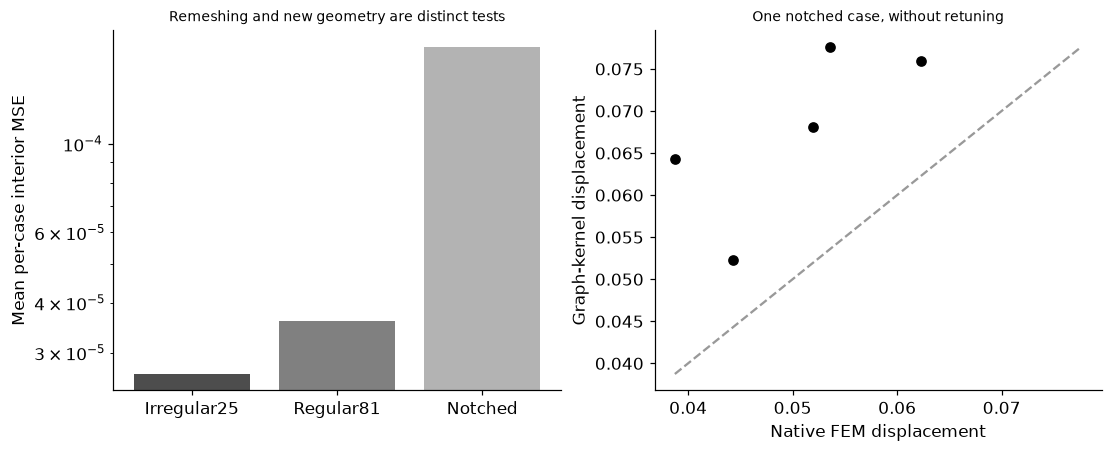

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(len(rows));axes[0].bar(xx,[r['mean_interior_MSE'] for r in rows],color=['.3','.5','.7']);axes[0].set(yscale='log',xticks=xx,xticklabels=['Irregular25','Regular81','Notched'],ylabel='Mean per-case interior MSE',title='Remeshing and new geometry are distinct tests');mesh=notched[0];pred=predict(mesh);inside=~mesh['boundary'];axes[1].scatter(mesh['truth'][inside],pred[inside],color='black');bounds=[min(mesh['truth'][inside].min(),pred[inside].min()),max(mesh['truth'][inside].max(),pred[inside].max())];axes[1].plot(bounds,bounds,'--',color='.6');axes[1].set(xlabel='Native FEM displacement',ylabel='Graph-kernel displacement',title='One notched case, without retuning');plt.show()
assert all(np.isfinite(r['mean_interior_MSE']) for r in rows) and all(r['max_boundary_defect']==0 for r in rows)


In [4]:
summary={'example_id':'code_136','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native triangular finite-element problem family', 'actual quadrature-weighted learned graph kernel', 'whole-mesh geometry assessment', 'node-permutation identity', 'new mesh resolution and notched domain'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native triangular finite-element problem family", "actual quadrature-weighted learned graph kernel", "whole-mesh geometry assessment", "node-permutation identity", "new mesh resolution and notched domain"], "elapsed_seconds": 4.249, "example_id": "code_136", "hardware": "Darwin arm64 CPU", "results": {"best_update": 400, "candidates": [{"best_update": 400, "development_MSE": 2.06033319319708e-05, "learning_rate": 0.003}, {"best_update": 400, "development_MSE": 5.904736737648079e-06, "learning_rate": 0.01}], "case_counts": [32, 8, 8, 12], "coarse_vs_finer_FEM_reference_RMS": [0.0014216127838767333, 0.0017852307184760365], "comparisons": [{"cases": 8, "cohort": "Rectangle final, irregular25", "max_boundary_defect": 0.0, "mean_case_field_MSE": 9.547232013623346e-06, "mean_interior_MSE": 2.652008892673151e-05, "node_counts": [25, 25, 25, 25, 25, 25, 25, 25]}, {"cases": 8, "cohort": "Rectangle final, regular81", "max_boundary_defect": 0.0, 